# Trolls, Haters, or Teammates - exploration & results
A walkthrough of the data, the models and the errors. Run `python train_model.py` first so `models/` is populated.

In [1]:
import sys, json, warnings
sys.path.insert(0, '..')
warnings.filterwarnings('ignore')
import pickle, pandas as pd
from src.data import load_split
from src.config import MODELS_DIR, LABELS
pd.set_option('display.max_colwidth', 80)
train, test = load_split('train'), load_split('test')
print(len(train), 'train /', len(test), 'test messages')

16912 train / 5949 test messages


## 1. The data
CONDA Dota 2 chat mapped onto the Stanford paper's three classes (see README for the mapping).

In [2]:
train['label'].value_counts().to_frame('train').join(test['label'].value_counts().to_frame('test'))

,train,test
label,,
Neutral / Positive,12552,4410
Derogatory,3220,1120
Negative attitude,1140,419


In [3]:
for label in LABELS:
    print('\n==', label)
    for t in train[train.label == label].sample(8, random_state=3).text: print('  -', t)


== Neutral / Positive
  - come in
  - damm themetric system
  - stop rat doto please
  - take that doom, what u waiting for?
  - plz no
  - gotta love a good loss coz of downs
  - he is in d2 but dont rec
  - haha 5 v 1?

== Negative attitude
  - ez geam
  - ks all game and say ez game wp necro
  - and ez pts
  - lol its abandon game
  - jug really?
  - you so mads brahs
  - ez 56 mins
  - funny how quiet you are

== Derogatory
  - had to carry noob troll xd from offalne xd
  - fuckin craos craps
  - your so fucking bad can u just afk
  - reported
  - shit invoke
  - ember is ruling and u sucking necro
  - zeus oruspı cpcugu go end gg go end please go end fuckng noob zeus
  - hes trash omfg


In [4]:
train['n_words'] = train['text'].str.split().str.len()
train.groupby('label')['n_words'].describe()[['mean', '50%', 'max']].round(1)

,mean,50%,max
label,,,
Derogatory,5.6,4.0,41.0
Negative attitude,4.7,4.0,26.0
Neutral / Positive,4.0,3.0,51.0


Chat messages are very short, which is why n-gram TF-IDF is a strong fit.

## 2. Model comparison

In [5]:
m = json.load(open(MODELS_DIR / 'metrics_baselines.json'))
rows = [{'model': n, 'features': r['features'], 'param': r['best_param'], 'accuracy': r['accuracy'], 'macro_F1': r['macro_f1'],
         'neg_attitude_F1': r['per_class']['Negative attitude']['f1-score'], 'ms/msg': r['latency_ms']} for n, r in m['results'].items()]
pd.DataFrame(rows).round(3)

,model,features,param,accuracy,macro_F1,neg_attitude_F1,ms/msg
0,K-NN,TF-IDF,101,0.856,0.695,0.506,29.173
1,Naive Bayes,TF-IDF,0.3,0.885,0.765,0.556,1.498
2,Logistic Regression,TF-IDF,1,0.897,0.799,0.589,1.363
3,Linear SVM,TF-IDF,0.1,0.920,0.822,0.643,2.249
4,Random Forest,TF-IDF,gini,0.914,0.815,0.639,10.102
5,MLP + GloVe,GloVe-50 (87% token coverage),"(128, 64)",0.838,0.683,0.534,0.172


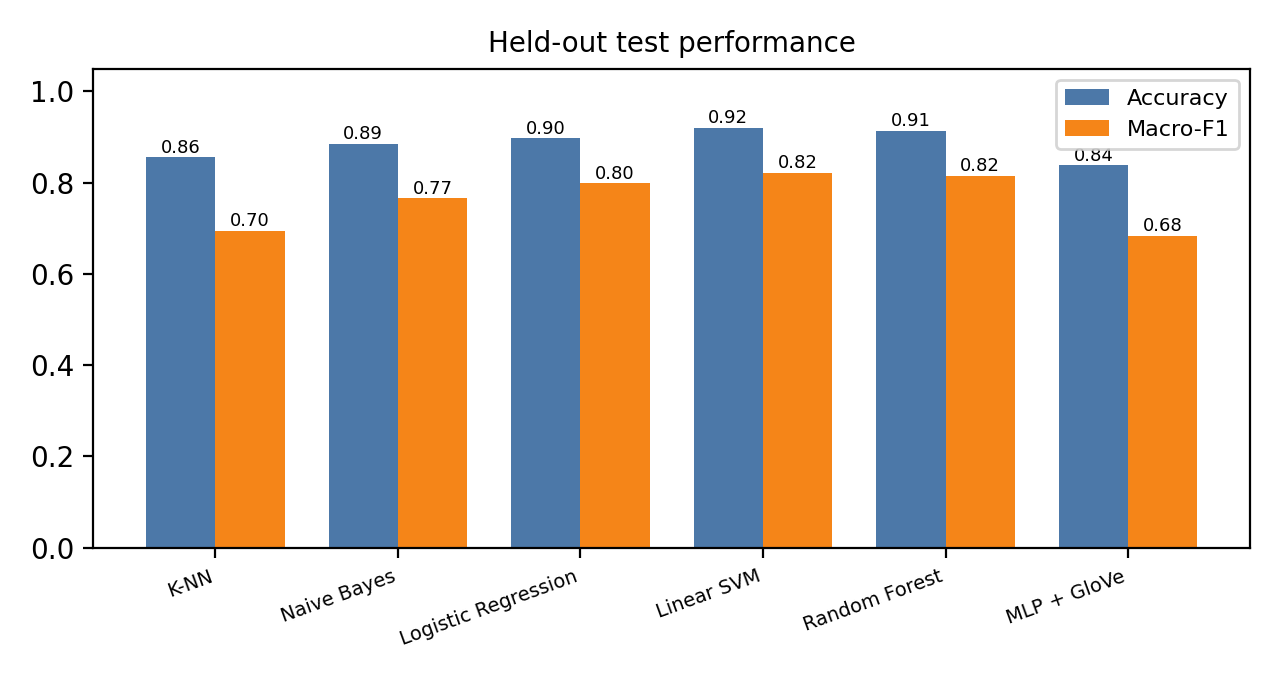

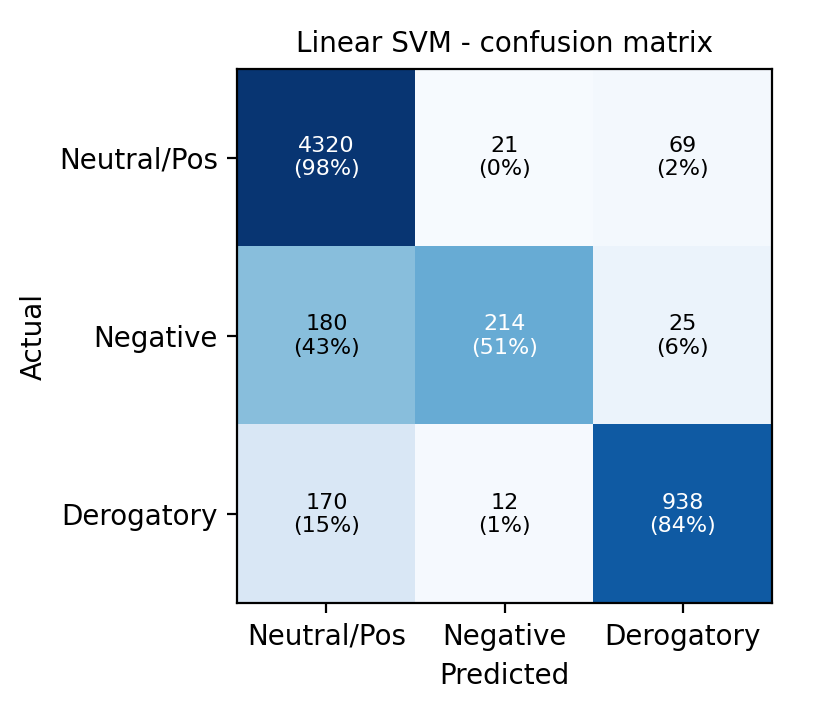

In [6]:
from IPython.display import Image, display
display(Image('../docs/figures/model_comparison.png', width=520))
display(Image('../docs/figures/confusion_matrix.png', width=380))

## 3. Is the score inflated by duplicate messages?
Short messages such as "gg" occur in both splits. Accuracy on messages never seen in training:

In [7]:
pd.Series(m['overlap']).round(3)

n_seen            751.000
share_seen          0.126
acc_seen            0.940
acc_novel           0.917
macro_f1_novel      0.815
dtype: float64

## 4. What does the model look at?
Highest-weight word features of the Logistic Regression model for each hostile class (explicit slurs omitted here).

In [8]:
bad = {'rape', 'gay', 'bitch', 'ass', 'cunt', 'dick', 'shit', '0', 'son'}
for cls, feats in m['top_features'].items():
    print(cls, '->', [f for f, w in feats if f not in bad][:9])

Negative attitude -> ['ez', '1k', 'mad', 'fucking ez', '2k', 'rocket', 'like you', 'kids', 'kid']
Derogatory -> ['noob', 'trash', 'idiot', 'stupid']


## 5. Error analysis
Random misclassifications of the deployed model on the test set.

In [9]:
pd.DataFrame(m['errors'], columns=['message', 'actual', 'predicted'])

,message,actual,predicted
0,wtf am ? use blink,Negative attitude,Neutral / Positive
1,ahahaha i love masturbating,Derogatory,Neutral / Positive
2,did you buy an account?,Negative attitude,Neutral / Positive
3,oh fuc kno solo ganked by io,Derogatory,Neutral / Positive
4,little insect for me,Derogatory,Neutral / Positive
5,i want to tap that ass for real,Neutral / Positive,Derogatory
6,bully sf like bull blind kid,Negative attitude,Neutral / Positive
7,typical brain dead russian disconnect after draft no surprise i hope america...,Neutral / Positive,Derogatory
8,cumback,Derogatory,Neutral / Positive
9,stop def idiots alyansov nasmotrelis?,Neutral / Positive,Derogatory


## 6. Try it

In [10]:
from src.preprocess import clean_text
model = pickle.load(open(MODELS_DIR / 'model.pkl', 'rb')); vec = pickle.load(open(MODELS_DIR / 'vectorizer.pkl', 'rb'))
def predict(msg):
    p = model.predict_proba(vec.transform([clean_text(msg)]))[0]
    return dict(zip(model.classes_, p.round(2)))
for msg in ['gg ez trash team uninstall', 'nice save, gg wp', 'push mid now', 'thanks for the heal', 'shut up and uninstall']:
    print(f'{msg!r:40}', predict(msg))

'gg ez trash team uninstall'             {'Derogatory': np.float64(0.87), 'Negative attitude': np.float64(0.13), 'Neutral / Positive': np.float64(0.0)}
'nice save, gg wp'                       {'Derogatory': np.float64(0.01), 'Negative attitude': np.float64(0.02), 'Neutral / Positive': np.float64(0.98)}
'push mid now'                           {'Derogatory': np.float64(0.05), 'Negative attitude': np.float64(0.07), 'Neutral / Positive': np.float64(0.88)}
'thanks for the heal'                    {'Derogatory': np.float64(0.01), 'Negative attitude': np.float64(0.02), 'Neutral / Positive': np.float64(0.97)}
'shut up and uninstall'                  {'Derogatory': np.float64(0.65), 'Negative attitude': np.float64(0.03), 'Neutral / Positive': np.float64(0.32)}
